In [8]:
!pip install 
!pip install folium

ERROR: You must give at least one requirement to install (see "pip help install")
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [folium]


In [3]:
#imports
import requests
import pandas as pd
import matplotlib.pyplot as plt
from pyproj import Transformer
import folium
import os

/opt/conda/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/conda/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


In [26]:
BASE_URL = "https://sinca.mma.gob.cl/cgi-bin/APUB-MMA/apub.tsindico2.cgi"

# Estaciones del gran concepción que miden MP2,5  -> despues podria medir para toda la region
# codigo: (nombre, comuna)
ESTACIONES = {
    "854": ("Punteras", "Chiguayante"),
    "827": ("Kingston College", "Concepcion"),
    "831": ("Cerro Merquin", "Coronel"),
    "878": ("Coronel Norte", "Coronel"),
    "880": ("Escuadron ENEL", "Coronel"),
    "881": ("Escuadron ENESA", "Coronel"),
    "879": ("Lagunillas ENEL", "Coronel"),
    "859": ("Lota rural", "Coronel"),
    "860": ("Lota urbana", "Coronel"),
    "805": ("Bocatoma", "Hualpen"),
    "838": ("ENAP Price", "Hualpen"),
    "804": ("JUNJI", "Hualpen"),
    "841": ("Hualqui", "Hualqui"),
    "802": ("Consultorio San Vicente", "Talcahuano"),
    "807": ("Indura", "Talcahuano"),
    "806": ("Inpesca", "Talcahuano"),
}

# Contaminantes que queremos traer, con su código SINCA
# nombre_legible: codigo_sinca
CONTAMINANTES = {
    "mp2.5": "PM25",
    "mp10":  "PM10",
    "so2":   "0001",
    "no":    "0002",
    "no2":   "0003",
    "co":    "0004",
    "o3":    "0008",
    "nox":   "0NOX",
}

In [12]:
def pedir_sinca(region,estacion_cod, parametro, desde, hasta):
    """
    Pide datos a SINCA y devuelve en texto crudo.
        - region: codigo de region (ej: bio bio -> RVIII)
        - estadion_cod : Código de la estacion (ej: "827" para Kingston College)
        - parametro: que medir (ej: "PM25", para MP2,5)
        - desde, hasta: fechas en formato AAMMDD (ej: "240101" => 1 enero 2024)

        sinca response => 240101;0100;23;;;
            - 240101 => 1 de enero 2024
            - 0100   => 01:00 hora 
            - 23;;     => 23 µg/m³ de MP2,5
             │ │ │
             │ │ └─ posición 3: NO validado
             │ └─── posición 2: preliminar
             └───── posición 1: validado
    """
    params = {
        "outtype": "xcl", # fromato de salida (texto/CSV)
        "macro": f"./{region}/{estacion_cod}/Cal/{parametro}/{parametro}.horario.horario.ic",
        "from": desde,
        "to": hasta,
        "path": "/usr/airviro/data/CONAMA/",
        "lang": "esp"
    }
    respuesta = requests.get(BASE_URL, params = params, timeout = 60)
    return respuesta.text

##Test de la funcion    
##texto = pedir_sinca("RVIII","827", "PM25", "240101", "240107")
##print(texto[:500])

In [21]:
def parsear_sinca(texto):
    """
    Convierte el texto crudo de SINCA en un tabla (dataframe).
    columnas de salida: timestamp, valor, estado
    """
    estados = ["validado","preliminar","no_validado"]
    filas = []
    
    for linea in texto.splitlines()[1:]:
        if not linea.strip():
            continue # saltamos las lineas vacias

        campos = linea.split(";")
        
        if len(campos) < 3:
            continue # saltamos linea incompleta

        fecha = campos[0].strip() # ej: "240101"
        hora = campos[1].strip()  # ej: "0100"
        timestamp = pd.to_datetime(fecha + hora[:2], format="%y%m%d%H")
        
        #buscamos el valor en las 3 posiciones posibles 2,3,4
        valor = None
        estado = None

        for i, nombre_estado in enumerate(estados):
            pos = 2 + i
            if pos < len(campos) and campos[pos].strip():
                valor = float(campos[pos].replace(",", "."))  # valor = float(campos[pos])
                estado = nombre_estado
                break

        if valor is None:
            continue #la hora no tenia medicion
    
        filas.append({"timestamp": timestamp, "valor": valor, "estado": estado})
    
    df = pd.DataFrame(filas)
    return df
## Test
##tabla = parsear_sinca(texto)
##print(tabla)

In [27]:
def traer_estaciones(estaciones, contaminantes, desde, hasta, region="RVIII"):
    """
    Recorre un diccionario de estaciones, pide cada una a SINCA,
    le agrega nombre/comuna, y junta todo en una sola tabla.
    """
    tablas = []

    for codigo, (nombre, comuna) in estaciones.items():
        for nombre_cont, codigo_cont in contaminantes.items():   # NUEVO: bucle de contaminantes

            print(f"Trayendo {nombre} / {nombre_cont}...", end=" ")
        
            # pedir y parsear (reusamos las funciones que ya hicimos)
            texto = pedir_sinca(region, codigo, codigo_cont, desde, hasta)
            tabla = parsear_sinca(texto)

            if tabla is None or len(tabla) == 0:
                print("sin datos")
                continue

            # agregar de qué estación es cada fila
            tabla["codigo"] = codigo
            tabla["estacion"] = nombre
            tabla["comuna"] = comuna
            tabla["parametro"] = nombre_cont

            tablas.append(tabla)
            print(f"{len(tabla)} registros")

    # juntar todas las tablas en una sola
    if not tablas:
        return None
    return pd.concat(tablas, ignore_index=True)


In [30]:
os.makedirs("data", exist_ok=True)
ARCHIVO = "data/contaminantes_gran_concepcion.csv"   # nombre nuevo (ya no es solo mp25)

if os.path.exists(ARCHIVO):
    datos = pd.read_csv(ARCHIVO, parse_dates=["timestamp"])
    print(f"Cargado desde {ARCHIVO}: {len(datos)} filas")
else:
    print("Descargando todo el histórico de todos los contaminantes... (tarda varios minutos)")
    datos = traer_estaciones(ESTACIONES, CONTAMINANTES, "110101", "260711")  # ahora CONTAMINANTES
    datos.to_csv(ARCHIVO, index=False)
    print(f"\nGuardado en {ARCHIVO}: {len(datos)} filas")

print(f"Estaciones: {datos['estacion'].nunique()}")
print(f"Parámetros: {datos['parametro'].unique()}")
print(f"Rango: {datos['timestamp'].min()} a {datos['timestamp'].max()}")

Descargando todo el histórico de todos los contaminantes... (tarda varios minutos)
Trayendo Punteras / mp2.5... 93614 registros
Trayendo Punteras / mp10... 125421 registros
Trayendo Punteras / so2... 80945 registros
Trayendo Punteras / no... 82501 registros
Trayendo Punteras / no2... 82777 registros
Trayendo Punteras / co... sin datos
Trayendo Punteras / o3... sin datos
Trayendo Punteras / nox... 82805 registros
Trayendo Kingston College / mp2.5... 95705 registros
Trayendo Kingston College / mp10... 124740 registros
Trayendo Kingston College / so2... 80243 registros
Trayendo Kingston College / no... 97988 registros
Trayendo Kingston College / no2... 99013 registros
Trayendo Kingston College / co... 118266 registros
Trayendo Kingston College / o3... 110632 registros
Trayendo Kingston College / nox... 100211 registros
Trayendo Cerro Merquin / mp2.5... 92773 registros
Trayendo Cerro Merquin / mp10... 105842 registros
Trayendo Cerro Merquin / so2... 21358 registros
Trayendo Cerro Merquin /

In [ ]:

# Carpeta donde guardar
os.makedirs("data", exist_ok=True)
ARCHIVO = "data/mp25_gran_concepcion.csv"

# Si el archivo ya existe, lo cargamos (rápido). Si no, lo descargamos (lento).
if os.path.exists(ARCHIVO):
    datos = pd.read_csv(ARCHIVO, parse_dates=["timestamp"])
    print(f"Cargado desde {ARCHIVO}: {len(datos)} filas")
else:
    print("Descargando todo el histórico... (esto tarda unos minutos)")
    datos = traer_estaciones(ESTACIONES, "PM25", "110101", "260711")  # 2011 a hoy
    datos.to_csv(ARCHIVO, index=False)
    print(f"\nGuardado en {ARCHIVO}: {len(datos)} filas")

print(f"Estaciones: {datos['estacion'].nunique()}")
print(f"Rango: {datos['timestamp'].min()} a {datos['timestamp'].max()}")

In [4]:
# Convertir a parquet (más liviano y rápido)
# Cargar el CSV (tarda, son 500 MB)
print("Cargando CSV...")
datos = pd.read_csv("data/contaminantes_gran_concepcion.csv", parse_dates=["timestamp"])
print(f"Cargado: {len(datos):,} filas")

# Guardar como parquet
print("Guardando parquet...")
datos.to_parquet("data/contaminantes_gran_concepcion.parquet", index=False)

# Comparar tamaños
csv_mb = os.path.getsize("data/contaminantes_gran_concepcion.csv") / 1024**2
pq_mb  = os.path.getsize("data/contaminantes_gran_concepcion.parquet") / 1024**2
print(f"\nCSV:     {csv_mb:.0f} MB")
print(f"Parquet: {pq_mb:.0f} MB")
print(f"Reducción: {100*(1-pq_mb/csv_mb):.0f}%")

Cargando CSV...
Cargado: 7,973,661 filas
Guardando parquet...

CSV:     503 MB
Parquet: 60 MB
Reducción: 88%


# Testeo de la data 

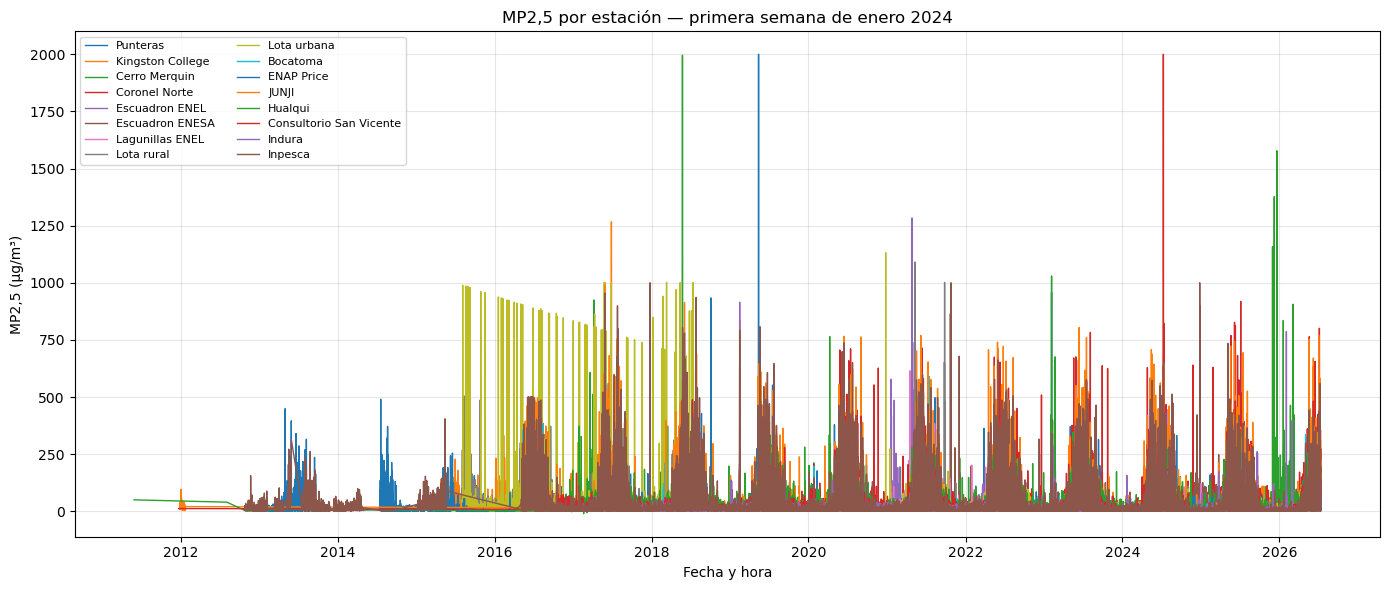

In [23]:
# Creamos la figura
fig, ax = plt.subplots(figsize=(14, 6))

# Dibujamos una línea por cada estación
for nombre in datos["estacion"].unique():
    # filtramos solo las filas de esa estación
    d = datos[datos["estacion"] == nombre]
    ax.plot(d["timestamp"], d["valor"], label=nombre, linewidth=1)

# Etiquetas y leyenda
ax.set_title("MP2,5 por estación — primera semana de enero 2024")
ax.set_xlabel("Fecha y hora")
ax.set_ylabel("MP2,5 (µg/m³)")
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
# Coordenadas UTM (huso 18 Sur). 
# "V" = verificada desde ficha oficial SINCA. "A" = aproximada (afinar después).
UTM_ESTACIONES = {
    "854": (674923, 5911833),   # Punteras, Chiguayante        - V
    "827": (673817, 5927247),   # Kingston College, Concepcion - V
    "831": (663500, 5905000),   # Cerro Merquin, Coronel       - A
    "878": (664000, 5915000),   # Coronel Norte, Coronel       - A
    "880": (662500, 5903000),   # Escuadron ENEL, Coronel      - A
    "881": (662400, 5902800),   # Escuadron ENESA, Coronel     - A
    "879": (663000, 5904000),   # Lagunillas ENEL, Coronel     - A
    "859": (664500, 5895000),   # Lota rural, Coronel          - A
    "860": (664200, 5894500),   # Lota urbana, Coronel         - A
    "805": (669000, 5931000),   # Bocatoma, Hualpen            - A
    "838": (668500, 5930500),   # ENAP Price, Hualpen          - A
    "804": (669500, 5931500),   # JUNJI, Hualpen               - A
    "841": (682000, 5910000),   # Hualqui, Hualqui             - A
    "802": (668000, 5933000),   # Consultorio San Vicente, Talcahuano - A
    "807": (670000, 5932000),   # Indura, Talcahuano           - A
    "806": (669000, 5932500),   # Inpesca, Talcahuano          - A
}

# Convertir todas a lat/lon
COORDENADAS = {}
for cod, (e, n) in UTM_ESTACIONES.items():
    COORDENADAS[cod] = utm_a_latlon(e, n)

for cod, (lat, lon) in COORDENADAS.items():
    print(f"{cod}: {lat}, {lon}")

854: -36.92332, -73.03612
827: -36.78465, -73.05206
831: -36.98693, -73.16283
878: -36.89675, -73.15938
880: -37.00512, -73.17363
881: -37.00694, -73.17471
879: -36.99603, -73.16823
859: -37.07685, -73.14941
860: -37.08141, -73.15268
805: -36.75171, -73.10685
838: -36.7563, -73.11234
804: -36.74711, -73.10136
841: -36.93849, -72.95627
802: -36.73387, -73.11849
807: -36.74252, -73.09588
806: -36.73819, -73.10718


In [25]:
# Calcular el MP2,5 promedio de cada estación (de los datos que ya tienes)
promedios = datos.groupby(["codigo", "estacion"])["valor"].mean().reset_index()

# Centro del mapa: Gran Concepción
mapa = folium.Map(location=[-36.90, -73.10], zoom_start=11)

# Agregar un punto por cada estación
for _, fila in promedios.iterrows():
    cod = fila["codigo"]
    if cod not in COORDENADAS:
        continue
    lat, lon = COORDENADAS[cod]
    valor = fila["valor"]

    folium.CircleMarker(
        location=[lat, lon],
        radius=8,
        popup=f"{fila['estacion']}: {valor:.1f} µg/m³",
        color="black",
        weight=1,
        fill=True,
        fill_color="red",
        fill_opacity=0.6,
    ).add_to(mapa)

# Mostrar el mapa
mapa

In [5]:
#from src.config import ESTACIONES, CONTAMINANTES
#print(len(ESTACIONES), len(CONTAMINANTES))

from src.config import ESTACIONES, CONTAMINANTES
from src.sinca import traer_estaciones

datos = traer_estaciones(ESTACIONES, CONTAMINANTES, "110101", "260711")

Trayendo Punteras / mp2.5... 93614 registros
Trayendo Punteras / mp10... 125421 registros
Trayendo Punteras / so2... 80945 registros
Trayendo Punteras / no... 82501 registros
Trayendo Punteras / no2... 82777 registros
Trayendo Punteras / co... sin datos
Trayendo Punteras / o3... sin datos
Trayendo Punteras / nox... 82805 registros
Trayendo Kingston College / mp2.5... 95705 registros
Trayendo Kingston College / mp10... 124740 registros
Trayendo Kingston College / so2... 80243 registros
Trayendo Kingston College / no... 97988 registros
Trayendo Kingston College / no2... 99013 registros
Trayendo Kingston College / co... 118266 registros
Trayendo Kingston College / o3... 110632 registros
Trayendo Kingston College / nox... 100211 registros
Trayendo Cerro Merquin / mp2.5... 92773 registros
Trayendo Cerro Merquin / mp10... 105842 registros
Trayendo Cerro Merquin / so2... 21358 registros
Trayendo Cerro Merquin / no... sin datos
Trayendo Cerro Merquin / no2... sin datos
Trayendo Cerro Merquin /

In [6]:
import os
os.makedirs("../data", exist_ok=True)
datos.to_parquet("../data/crudo.parquet", index=False)
print(f"Guardado: {len(datos):,} filas")

ImportError: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
 - Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.